# 03. Baseline Model (TF-IDF + Logistic Regression)

- **Role/Owner:** Member 1 (Full-Stack & Integration Lead)
- **Core Responsibility:** Train and evaluate traditional NLP baseline (TF-IDF vectorizer + Logistic Regression) for rubric compliance and Transformer performance comparison.
- **Key Interface/Contract:** Consumes cleaned text splits; outputs `backend/models/tfidf_logreg.joblib` and baseline evaluation metrics.

**Inputs:** `backend/data/processed/{train,val,test}.csv` from notebook 02 (`text_clean`, `label` with 1 = false: a PHEME rumour annotated false or a PolitiFact fake title, `source`, `event`, `veracity`), and the evaluation-only contrast set `backend/data/eval/contrast_set.csv`.

**Outputs:**
- `backend/models/tfidf_logreg.joblib`: a dictionary holding the fitted scikit-learn pipeline (TF-IDF vectoriser + Logistic Regression) and what the backend needs to use it. Same layout as `spread_regressor.joblib`: the model is `art["model"]`.
- `backend/reports/tfidf_logreg_metrics.json`: test metrics, per-source scores, unseen-event scores, the validation grid, the strongest terms, the cross-check against `split_baselines.md`, the Control Test and the contrast set. The keys `accuracy`, `precision`, `recall`, `macro_f1` and `confusion_matrix` are the same as in `distilbert_metrics.json`.

**What this notebook does**

1. Load the three splits from notebook 02 and assert that they are the ones the other notebooks expect.
2. Define one scikit-learn pipeline: TF-IDF features into a Logistic Regression.
3. Tune three settings on the validation split only.
4. Score the test split once and compare with the "always factual" reference.
5. Repeat the test on PHEME events the model has never seen.
6. Read the coefficients to see what the model relies on.
7. Score the three Control Test sentences and the frozen contrast set, as notebook 04 does for DistilBERT.
8. Save the pipeline and the metrics, then reload the file the way the backend will.

**Evaluation protocol:** model selection uses validation Macro F1 only; the test split is scored once. The unseen-event runs reuse notebook 02 Part 10 (the same protocol as notebook 04 Part 6): hold out each PHEME event with at least 100 threads and at least 10 false threads, train on everything else, score on the held-out event. The positive class is misinformation (`label = 1`).

**Where it runs:** locally on CPU, no GPU needed. The full run takes well under a minute.

In [1]:
# Role/Owner: Member 1 (Full-Stack & Integration Lead)
# Core Responsibility: Baseline model training and benchmark
# Key Interface/Contract: Input: preprocessed data -> Output: backend/models/tfidf_logreg.joblib

import hashlib
import itertools
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline

sys.path.insert(0, '..')  # make backend/ importable so the API's cleaning function is the one used here
from app.services.preprocessor import preprocess_political_text

SEED = 42
LABELS = {0: 'factual', 1: 'misinformation'}
MIN_EVENT_THREADS = 100
MIN_EVENT_FALSE = 10

DATA_DIR = Path('../data/processed')
MODELS_DIR = Path('../models')
REPORTS_DIR = Path('../reports')
MODEL_PATH = MODELS_DIR / 'tfidf_logreg.joblib'
METRICS_PATH = REPORTS_DIR / 'tfidf_logreg_metrics.json'
BASELINES_PATH = REPORTS_DIR / 'split_baselines.md'
CONTRAST_PATH = Path('../data/eval/contrast_set.csv')

# The notebook 02 splits this notebook was run on, and the frozen contrast set (same hash as notebook 04).
SPLIT_SHA256 = {'train': 'e17a4981c179311601b1f8dc391034a57c370ae1f1dc60af1b7a41ab4d7c9bc2',
                'val': '7bc4cad17c177d2b94b23a8cfa88240936d8e3c3d6353b29f20cdcfd560020d1',
                'test': '675afb20fc0551cbb9ec169df71beb535564ea12d66a5759193386675878c5ae'}
CONTRAST_SHA256 = '2d4d4bbf9c91afe353c98eceea2123b293daa77569c52eb0e6d7b156b78c0ba9'  # frozen v1

NOTEBOOK_START = time.time()
print(f'scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}')

scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.4.6


## Part 1: Data

The deduped splits from notebook 02. Required columns, row counts, file SHA-256 hashes, label values and cross-split text overlap are asserted so a stale CSV fails here, not halfway through the run. The input is `text_clean`, the same column DistilBERT reads in notebook 04, so both models see identical text.

The second table shows why the `source` column matters for everything that follows: PolitiFact titles are about 43% misinformation, PHEME rumours only about 7%.

In [2]:
train_df, val_df, test_df = (pd.read_csv(DATA_DIR / f'{name}.csv') for name in ('train', 'val', 'test'))
for df in (train_df, val_df, test_df):
    df['text_clean'] = df['text_clean'].fillna('')
splits = {'train': train_df, 'val': val_df, 'test': test_df}

REQUIRED_COLUMNS = {'text_clean', 'label', 'source', 'event', 'veracity'}
assert all(REQUIRED_COLUMNS <= set(df.columns) for df in splits.values()), 'missing columns: re-check notebook 02'
assert (len(train_df), len(val_df), len(test_df)) == (4443, 952, 953), 'split sizes changed: re-check notebook 02'
for name in splits:
    digest = hashlib.sha256((DATA_DIR / f'{name}.csv').read_bytes()).hexdigest()
    assert digest == SPLIT_SHA256[name], f'{name}.csv changed (SHA-256 {digest}): re-check notebook 02'
assert all(set(df['label'].unique()) <= {0, 1} for df in splits.values())
for a, b in (('train', 'val'), ('train', 'test'), ('val', 'test')):
    shared = set(splits[a]['text_clean']) & set(splits[b]['text_clean'])
    assert not shared, f'{len(shared)} texts appear in both {a} and {b}: re-check the dedupe in notebook 02'

X_train, y_train = train_df['text_clean'], train_df['label']
X_val, y_val = val_df['text_clean'], val_df['label']
X_test, y_test = test_df['text_clean'], test_df['label']

split_summary = pd.DataFrame([
    {'split': name, 'rows': len(df), 'misinformation rate': df['label'].mean(),
     'pheme': int((df['source'] == 'pheme').sum()), 'politifact': int((df['source'] == 'politifact').sum())}
    for name, df in splits.items()])
display(split_summary.round(3))

print('Misinformation rate by source:')
display(pd.DataFrame({name: df.groupby('source')['label'].mean() for name, df in splits.items()}).round(3))

words = train_df['text_clean'].str.split().str.len()
print(f'Words per training text: mean {words.mean():.1f}, median {words.median():.0f}, max {words.max()}')

,split,rows,misinformation rate,pheme,politifact
0,train,4443,0.129,3757,686
1,val,952,0.129,805,147
2,test,953,0.129,805,148


Misinformation rate by source:


,train,val,test
source,,,
pheme,0.073,0.073,0.073
politifact,0.434,0.435,0.432


Words per training text: mean 15.7, median 16, max 53


## Part 2: The pipeline

One scikit-learn `Pipeline`, so the vectoriser and the classifier are saved, loaded and applied as a single object: the backend passes in a cleaned string and gets a probability back. Fitting happens on the training split only, so no vocabulary or IDF weight is ever learned from validation or test text.

| Setting | Value | Reason |
|---|---|---|
| `lowercase` | `True` | `distilbert-base-uncased` also ignores case, so the two models read case the same way. |
| `sublinear_tf` | `True` | Texts are only about 16 words, so a word rarely repeats; log-scaling stops a repeated token from dominating the vector. |
| `min_df` | `2` | A term seen in a single training text cannot generalise. Dropping it removes noise and keeps the saved file small. |
| `ngram_range` | tuned: 1-1 or 1-2 | Bigrams can capture short phrases such as "no evidence"; validation decides whether they help. |
| `C` | tuned | Inverse strength of the L2 penalty. A small `C` gives a simpler, more cautious model. |
| `class_weight` | tuned: none or `balanced` | Misinformation is about 13% of the rows. `balanced` weights each class by its inverse frequency, the same idea as the weighted cross-entropy in notebook 04. |
| `solver`, `max_iter` | `lbfgs`, 1000 | The default solver is deterministic; the higher limit makes sure it converges. |
| Decision rule | P(misinformation) >= 0.5 | The same argmax rule DistilBERT uses, so the comparison is like for like. |

In [3]:
def make_pipeline(ngram_range=(1, 2), C=1.0, class_weight=None) -> Pipeline:
    return Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, sublinear_tf=True, min_df=2, ngram_range=ngram_range)),
        ('logreg', LogisticRegression(C=C, class_weight=class_weight, max_iter=1000, random_state=SEED)),
    ])


def macro_scores(y_true, y_pred) -> dict:
    # The four numbers notebook 04 reports: accuracy plus macro-averaged precision, recall and F1.
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'macro_f1': f1_score(y_true, y_pred, average='macro')}


make_pipeline()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no char

## Part 3: Tuning on the validation split

A small grid over `ngram_range` x `C` x `class_weight` (2 x 9 x 2 = 36 fits). `C` runs from 0.1 to 1000 on purpose: a best value on the edge of the grid would mean the search stopped too early, so the cell prints a warning if that happens. Every fit uses the training split only and is scored on the validation split with Macro F1, the same selection metric as notebook 04. Macro F1 is used rather than accuracy because about 87% of the rows are factual: always answering "factual" already scores 0.87 accuracy but only 0.47 Macro F1. Ties are broken toward the smaller `C`, the more regularised model. The test split is not touched here.

36 fits in 6s
Best on validation: {'ngram_range': (1, 2), 'C': 30.0, 'class_weight': 'balanced'} -> Macro F1 0.8337 (always "factual": 0.4655)


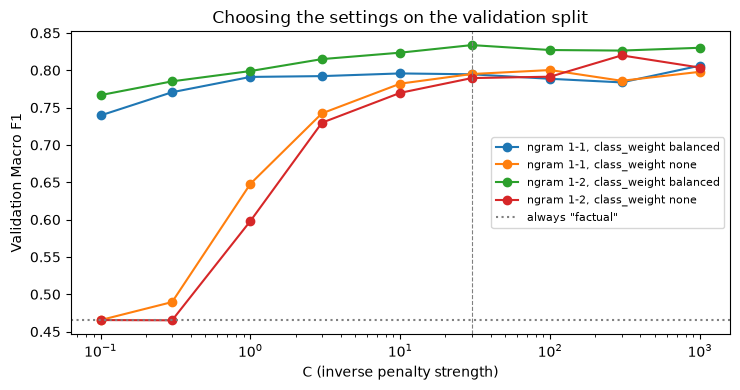

,ngram_range,C,class_weight,vocabulary,train_macro_f1,val_macro_f1
0,1-2,30.0,balanced,10764,0.9970,0.8337
1,1-2,1000.0,balanced,10764,0.9980,0.8301
2,1-2,100.0,balanced,10764,0.9975,0.8271
3,1-2,300.0,balanced,10764,0.9965,0.8264
4,1-2,10.0,balanced,10764,0.9882,0.8236
5,1-2,300.0,none,10764,0.9980,0.8199
6,1-2,3.0,balanced,10764,0.9577,0.8150
7,1-1,1000.0,balanced,3640,0.9930,0.8062


In [4]:
GRID = {'ngram_range': [(1, 1), (1, 2)], 'C': [0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000], 'class_weight': [None, 'balanced']}

majority = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
majority_val_f1 = f1_score(y_val, majority.predict(X_val), average='macro')

rows = []
tune_start = time.time()
for ngram_range, C, class_weight in itertools.product(GRID['ngram_range'], GRID['C'], GRID['class_weight']):
    fitted = make_pipeline(ngram_range, C, class_weight).fit(X_train, y_train)
    rows.append({'ngram_range': f'{ngram_range[0]}-{ngram_range[1]}', 'C': C, 'class_weight': class_weight or 'none',
                 'vocabulary': len(fitted.named_steps['tfidf'].vocabulary_),
                 'train_macro_f1': f1_score(y_train, fitted.predict(X_train), average='macro'),
                 'val_macro_f1': f1_score(y_val, fitted.predict(X_val), average='macro')})
grid_df = pd.DataFrame(rows)
grid_sorted = grid_df.sort_values(['val_macro_f1', 'C'], ascending=[False, True]).reset_index(drop=True)

best = grid_sorted.iloc[0]
BEST = {'ngram_range': tuple(int(n) for n in best['ngram_range'].split('-')), 'C': float(best['C']),
        'class_weight': None if best['class_weight'] == 'none' else best['class_weight']}
best_val_f1 = float(best['val_macro_f1'])
print(f'{len(grid_df)} fits in {time.time() - tune_start:.0f}s')
if BEST['C'] in (min(GRID['C']), max(GRID['C'])):
    print('WARNING: the best C is on the edge of the grid; widen GRID["C"] and rerun.')
print(f'Best on validation: {BEST} -> Macro F1 {best_val_f1:.4f} (always "factual": {majority_val_f1:.4f})')

fig, ax = plt.subplots(figsize=(7.5, 4))
for (ngram, weight), group in grid_df.groupby(['ngram_range', 'class_weight']):
    ax.plot(group['C'], group['val_macro_f1'], marker='o', label=f'ngram {ngram}, class_weight {weight}')
ax.axhline(majority_val_f1, color='gray', linestyle=':', label='always "factual"')
ax.axvline(BEST['C'], color='gray', linestyle='--', linewidth=0.8)
ax.set(xscale='log', xlabel='C (inverse penalty strength)', ylabel='Validation Macro F1', title='Choosing the settings on the validation split')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

display(grid_sorted.head(8).round(4))

## Part 4: Test-set evaluation (scored once)

The best configuration is refitted on the training split (not on train + validation, so the numbers describe exactly the model that is saved) and the untouched test split is scored. Positive class = misinformation.

Besides the four macro scores that notebook 04 reports, the cell prints ROC AUC and average precision. They do not depend on the 0.5 cut-off, which makes them informative when only 13% of the rows are positive.

                precision    recall  f1-score   support

       factual      0.951     0.961     0.956       830
misinformation      0.719     0.667     0.692       123

      accuracy                          0.923       953
     macro avg      0.835     0.814     0.824       953
  weighted avg      0.921     0.923     0.922       953

ROC AUC 0.925 | average precision 0.777 (a random scorer gets 0.129)
Macro F1: TF-IDF + LogReg 0.824 vs always-factual 0.466; accuracy 0.923 vs 0.871


,Source,Rows,Misinformation rate,Macro F1
0,pheme,805,0.073,0.817
1,politifact,148,0.432,0.763


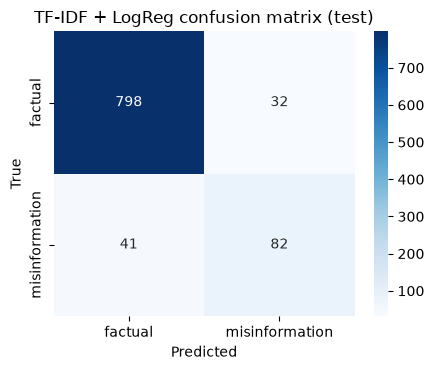

In [5]:
model = make_pipeline(**BEST).fit(X_train, y_train)
test_probs = model.predict_proba(X_test)[:, 1]
test_pred = model.predict(X_test)
assert (test_pred == (test_probs >= 0.5)).all(), 'predict() and the 0.5 rule disagree'

test_metrics = macro_scores(y_test, test_pred)
tn, fp, fn, tp = (int(v) for v in confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel())
misinfo_class = {'precision': precision_score(y_test, test_pred, zero_division=0),
                 'recall': recall_score(y_test, test_pred), 'f1': f1_score(y_test, test_pred)}
roc_auc = roc_auc_score(y_test, test_probs)
avg_precision = average_precision_score(y_test, test_probs)
majority_test = macro_scores(y_test, majority.predict(X_test))

print(classification_report(y_test, test_pred, target_names=list(LABELS.values()), digits=3))
print(f"ROC AUC {roc_auc:.3f} | average precision {avg_precision:.3f} (a random scorer gets {y_test.mean():.3f})")
print(f"Macro F1: TF-IDF + LogReg {test_metrics['macro_f1']:.3f} vs always-factual {majority_test['macro_f1']:.3f}; "
      f"accuracy {test_metrics['accuracy']:.3f} vs {majority_test['accuracy']:.3f}")

per_source = pd.DataFrame([
    {'Source': source, 'Rows': int(mask.sum()), 'Misinformation rate': y_test[mask].mean(),
     'Macro F1': f1_score(y_test[mask], test_pred[mask], average='macro')}
    for source in ('pheme', 'politifact') for mask in [(test_df['source'] == source).to_numpy()]])
display(per_source.round(3))

plt.figure(figsize=(4.5, 3.8))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt='d', cmap='Blues',
            xticklabels=list(LABELS.values()), yticklabels=list(LABELS.values()))
plt.title('TF-IDF + LogReg confusion matrix (test)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.show()

## Part 5: Events the model never saw

Same protocol as notebook 02 Part 10 and notebook 04 Part 6, so the numbers sit beside DistilBERT directly. For each PHEME event with at least 100 threads and at least 10 false threads (fewer false threads leave Macro F1 resting on a handful of rows): a fresh TF-IDF + Logistic Regression with the settings chosen in Part 3 is fitted on every other PHEME event plus the PolitiFact training rows, then scored on the held-out event. No validation-based selection happens here, because the held-out event must not influence training.

Macro F1 is the headline number, as in notebook 04. Recall of the misinformation class and ROC AUC are added to show *why* it moves, and the always-"factual" Macro F1 on the same event gives the floor: recall says how many false threads are found, AUC says whether the model ranks false threads above factual ones at all (0.5 = no better than chance).

In [6]:
pheme_pool = pd.concat([train_df, val_df, test_df]).query("source == 'pheme'")
event_sizes = pheme_pool['event'].value_counts()
event_false = pheme_pool.groupby('event')['label'].sum()
held_out_events = sorted(e for e in event_sizes.index
                         if event_sizes[e] >= MIN_EVENT_THREADS and event_false[e] >= MIN_EVENT_FALSE)
politifact_train = train_df[train_df['source'] == 'politifact']

print('PHEME events and whether they are held out:')
display(pd.DataFrame({'threads': event_sizes, 'false threads': event_false})
        .assign(**{'held out': lambda d: d.index.isin(held_out_events)}))

event_rows = []
for event in held_out_events:
    fit_df = pd.concat([pheme_pool[pheme_pool['event'] != event], politifact_train])
    eval_df = pheme_pool[pheme_pool['event'] == event]
    event_model = make_pipeline(**BEST).fit(fit_df['text_clean'], fit_df['label'])
    event_probs = event_model.predict_proba(eval_df['text_clean'])[:, 1]
    event_pred = (event_probs >= 0.5).astype(int)
    event_rows.append({'Event': event, 'Threads': len(eval_df), 'Misinformation': int(eval_df['label'].sum()),
                       'Factual': int((eval_df['label'] == 0).sum()),
                       'TF-IDF': f1_score(eval_df['label'], event_pred, average='macro'),
                       'Always factual': f1_score(eval_df['label'], np.zeros(len(eval_df), dtype=int), average='macro'),
                       'Misinformation recall': recall_score(eval_df['label'], event_pred),
                       'ROC AUC': roc_auc_score(eval_df['label'], event_probs)})
    print(f"{event}: Macro F1 {event_rows[-1]['TF-IDF']:.3f}")

event_df = pd.DataFrame(event_rows)
unseen_f1 = event_df['TF-IDF'].mean()
majority_unseen_f1 = event_df['Always factual'].mean()
print(f"Mean over {len(event_df)} events: {unseen_f1:.3f} (random-split test: {test_metrics['macro_f1']:.3f}; "
      f"{unseen_f1 / test_metrics['macro_f1']:.0%} kept; always factual: {majority_unseen_f1:.3f})")
print(f"Mean misinformation recall {event_df['Misinformation recall'].mean():.2f} | mean ROC AUC {event_df['ROC AUC'].mean():.3f} "
      f"(random-split test: recall {misinfo_class['recall']:.2f}, ROC AUC {roc_auc:.3f})")
display(event_df.round(3))

PHEME events and whether they are held out:


,threads,false threads,held out
event,,,
charliehebdo-all-rnr-threads,1884,113,True
ferguson-all-rnr-threads,854,7,False
germanwings-crash-all-rnr-threads,433,109,True
gurlitt-all-rnr-threads,120,0,False
ottawashooting-all-rnr-threads,810,72,True
putinmissing-all-rnr-threads,121,9,False
sydneysiege-all-rnr-threads,1145,84,True


charliehebdo-all-rnr-threads: Macro F1 0.526


germanwings-crash-all-rnr-threads: Macro F1 0.545


ottawashooting-all-rnr-threads: Macro F1 0.522
sydneysiege-all-rnr-threads: Macro F1 0.529
Mean over 4 events: 0.530 (random-split test: 0.824; 64% kept; always factual: 0.468)
Mean misinformation recall 0.20 | mean ROC AUC 0.616 (random-split test: recall 0.67, ROC AUC 0.925)


,Event,Threads,Misinformation,Factual,TF-IDF,Always factual,Misinformation recall,ROC AUC
0,charliehebdo-all-rnr-threads,1884,113,1771,0.526,0.485,0.230,0.567
1,germanwings-crash-all-rnr-threads,433,109,324,0.545,0.428,0.257,0.629
2,ottawashooting-all-rnr-threads,810,72,738,0.522,0.477,0.167,0.594
3,sydneysiege-all-rnr-threads,1145,84,1061,0.529,0.481,0.155,0.673


### Cross-check with `split_baselines.md`

Notebook 04 takes its TF-IDF reference numbers from `backend/reports/split_baselines.md`, which notebook 02 wrote. This notebook tunes its own settings, so the two TF-IDF numbers can differ a little. The cell prints both when the file is present, so a mismatch is visible before the comparison with DistilBERT is reported, and keeps both in `tfidf_cross_check` for the metrics JSON. `split_baselines.md` itself is not overwritten.

In [7]:
def read_tfidf_baselines(path: Path) -> tuple[float, float, dict[str, float]]:
    # Same parser as notebook 04: random-split and unseen-event Macro F1 of 'TF-IDF on cleaned text', plus per-event.
    lines = path.read_text().splitlines()
    cells = lambda line: [c.strip() for c in line.strip().strip('|').split('|')]
    summary = cells(next(l for l in lines if l.startswith('| TF-IDF on cleaned text |')))
    per_event, header = {}, None
    for line in lines[lines.index('## Per-event Macro F1 (held-out event)') + 1:]:
        if not line.startswith('|'):
            if header:
                break
            continue
        row = cells(line)
        if header is None:
            header = row
        elif not set(row[0]) <= set('-'):
            per_event[row[0]] = float(row[header.index('TF-IDF')])
    return float(summary[1]), float(summary[2]), per_event


if BASELINES_PATH.exists():
    ref_random_f1, ref_unseen_f1, ref_per_event = read_tfidf_baselines(BASELINES_PATH)
    print(f"{'':28s}{'random split':>14s}{'unseen events':>15s}")
    print(f"{'split_baselines.md (02)':28s}{ref_random_f1:>14.3f}{ref_unseen_f1:>15.3f}")
    print(f"{'this notebook':28s}{test_metrics['macro_f1']:>14.3f}{unseen_f1:>15.3f}")
    if abs(ref_random_f1 - test_metrics['macro_f1']) > 0.02 or abs(ref_unseen_f1 - unseen_f1) > 0.02:
        print('Differ by more than 0.02: align the settings with notebook 02 or report both numbers.')
    tfidf_cross_check = {
        'split_baselines_md': {'macro_f1': ref_random_f1, 'unseen_event_macro_f1': ref_unseen_f1,
                               'note': 'notebook 02 reference settings; what notebook 04 reads'},
        'tuned': {'macro_f1': test_metrics['macro_f1'], 'unseen_event_macro_f1': unseen_f1,
                  'note': 'this notebook, settings chosen on validation Macro F1'}}
else:
    print(f'{BASELINES_PATH} not found: cross-check skipped.')
    tfidf_cross_check = None

                              random split  unseen events
split_baselines.md (02)              0.784          0.541
this notebook                        0.824          0.530
Differ by more than 0.02: align the settings with notebook 02 or report both numbers.


## Part 6: What the model learned

Logistic Regression is a linear model, so its coefficients can be read directly: a positive coefficient pushes a text toward misinformation, a negative one toward factual. Being able to show this is the main reason to keep a linear baseline next to the Transformer.

These are associations in this dataset, not proof that a word is misleading. In particular, `[URL]` and `@USER` are placeholders that notebook 02 leaves in PHEME tweets and that PolitiFact titles never contain, so a model can use them as a source marker. The last lines of the cell print their coefficients. The table counts, for the five strongest terms on each side, how many training texts contain the term, how many of those are false, and whether they come from PolitiFact or mostly from one PHEME event.

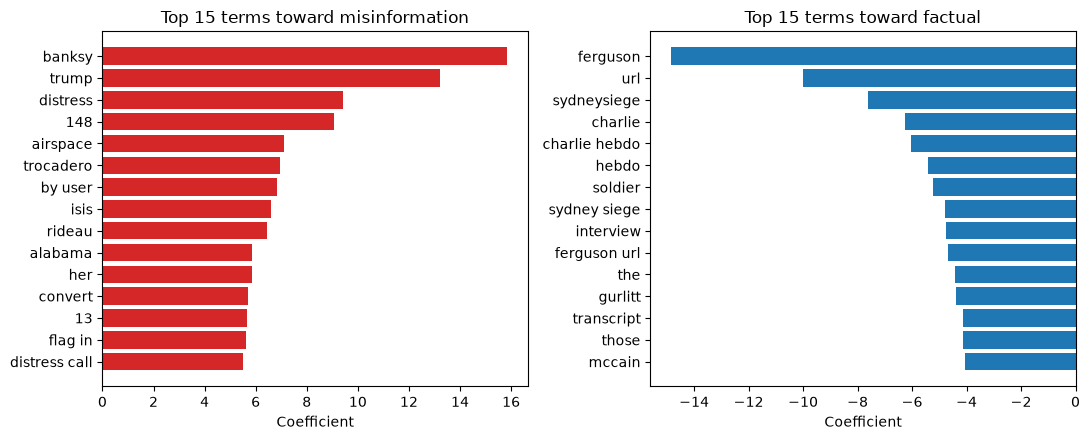

coefficient of "url" (from [URL] / @USER): -10.014
coefficient of "user" (from [URL] / @USER): -1.096
Vocabulary: 10,764 terms


Share of training texts with the [URL] token: PHEME 66%, PolitiFact 0%


,coefficient,training texts,false rate,PolitiFact share,main event,main event share
term,,,,,,
banksy,15.851,19,0.947,0.000,charliehebdo,1.000
trump,13.219,90,0.789,0.956,charliehebdo,0.022
distress,9.429,19,1.000,0.000,germanwings-crash,1.000
148,9.055,17,0.882,0.000,germanwings-crash,1.000
airspace,7.091,7,1.000,0.000,sydneysiege,1.000
ferguson,-14.864,608,0.010,0.000,ferguson,0.997
url,-10.014,2490,0.076,0.000,charliehebdo,0.400
sydneysiege,-7.624,345,0.038,0.000,sydneysiege,1.000
charlie,-6.268,1117,0.054,0.000,charliehebdo,1.000


In [8]:
vectorizer, classifier = model.named_steps['tfidf'], model.named_steps['logreg']
terms = np.array(vectorizer.get_feature_names_out())
coefs = classifier.coef_[0]
order = np.argsort(coefs)
TOP_N = 15

top_misinfo = pd.DataFrame({'term': terms[order[::-1][:TOP_N]], 'coefficient': coefs[order[::-1][:TOP_N]]})
top_factual = pd.DataFrame({'term': terms[order[:TOP_N]], 'coefficient': coefs[order[:TOP_N]]})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(top_misinfo['term'][::-1], top_misinfo['coefficient'][::-1], color='tab:red')
axes[0].set(title=f'Top {TOP_N} terms toward misinformation', xlabel='Coefficient')
axes[1].barh(top_factual['term'][::-1], top_factual['coefficient'][::-1], color='tab:blue')
axes[1].set(title=f'Top {TOP_N} terms toward factual', xlabel='Coefficient')
plt.tight_layout()
plt.show()

term_index = {term: i for i, term in enumerate(terms)}
for token in ('url', 'user'):
    if token in term_index:
        print(f'coefficient of "{token}" (from [URL] / @USER): {coefs[term_index[token]]:+.3f}')
print(f'Vocabulary: {len(terms):,} terms')

analyze = vectorizer.build_analyzer()
train_tokens = train_df['text_clean'].map(lambda text: set(analyze(text)))


def term_stats(term: str) -> dict:
    rows = train_df[train_tokens.map(lambda tokens: term in tokens).to_numpy()]
    events = rows.loc[rows['source'] == 'pheme', 'event'].value_counts()
    return {'term': term, 'coefficient': coefs[term_index[term]], 'training texts': len(rows),
            'false rate': rows['label'].mean(), 'PolitiFact share': (rows['source'] == 'politifact').mean(),
            'main event': events.index[0].removesuffix('-all-rnr-threads') if len(events) else '-',
            'main event share': events.iloc[0] / len(rows) if len(events) else 0.0}


term_df = pd.DataFrame([term_stats(t) for t in [*top_misinfo['term'][:5], *top_factual['term'][:5]]]).set_index('term')
pheme_train = train_df['source'] == 'pheme'
url_share = {source: train_tokens[train_df['source'] == source].map(lambda tokens: 'url' in tokens).mean()
             for source in ('pheme', 'politifact')}
print(f"Share of training texts with the [URL] token: PHEME {url_share['pheme']:.0%}, PolitiFact {url_share['politifact']:.0%}")
display(term_df.round(3))

## Part 7: Control Test and contrast set

The same two checks notebook 04 runs on DistilBERT (its Parts 7 and 8), applied to the TF-IDF pipeline so the two models are judged on the same sentences. Both are cleaned with `preprocess_political_text`, the function the API uses, and are **for evaluation only**: nothing here feeds back into training or the choice of settings.

- **Control Test:** the three demo sentences from `docs/political-misinfo-plan.md`, with the same expected labels and confidence bars as notebook 04.
- **Contrast set:** the frozen `backend/data/eval/contrast_set.csv` (the cell stops if its SHA-256 changed). `style_aligned` pairs follow the Control Test pattern (neutral fact, sensational misinformation); `style_crossed` pairs swap the styles. **Style-balanced accuracy**, the mean accuracy over the label x style cells, is the headline. The regex style baseline predicts misinformation when the raw text has a 4+ letter all-caps word, `!!` or "share"; a model reads more than style only if it beats that row by more than the noise margin.

In [9]:
CONTROL_TESTS = [
    ('Misinformation input',
     'BREAKING: Leaked documents confirm election officials destroyed 50,000 valid ballots overnight in swing state. '
     '#StopTheSteal #ElectionFraud SHARE NOW!!!', 'misinformation', 0.90),
    ('Factual input (same keywords)',
     'Election officials confirmed all 50,000 ballots were securely audited and counted following standard legal '
     'verification procedures, with bipartisan observers present throughout.', 'factual', 0.85),
    ('Edge case: sensational punctuation',
     "Ferguson police cover-up EXPOSED!!! Media won't tell you this!!! #Ferguson #TruthMatters",
     'misinformation', None),
]

control_rows = []
for name, text, expected, min_confidence in CONTROL_TESTS:
    cleaned = preprocess_political_text(text)
    probs = model.predict_proba([cleaned])[0]
    label = LABELS[int(model.predict([cleaned])[0])]
    passed = label == expected and (min_confidence is None or probs.max() >= min_confidence)
    control_rows.append({'Case': name, 'Cleaned text': cleaned, 'Expected': expected,
                         'Required confidence': '-' if min_confidence is None else f'>= {min_confidence:.0%}',
                         'Predicted': label, 'Confidence': float(probs.max()),
                         'P(misinformation)': float(probs[1]), 'Result': 'pass' if passed else 'fail'})

control_df = pd.DataFrame(control_rows)
control_passed = int((control_df['Result'] == 'pass').sum())
print(f'Control Test: {control_passed} of {len(control_df)} passed')
display(control_df.drop(columns='Cleaned text').round(3))

Control Test: 1 of 3 passed


,Case,Expected,Required confidence,Predicted,Confidence,P(misinformation),Result
0,Misinformation input,misinformation,>= 90%,misinformation,0.957,0.957,pass
1,Factual input (same keywords),factual,>= 85%,factual,0.663,0.337,fail
2,Edge case: sensational punctuation,misinformation,-,factual,0.998,0.002,fail


In [10]:
contrast_sha256 = hashlib.sha256(CONTRAST_PATH.read_bytes()).hexdigest()
assert contrast_sha256 == CONTRAST_SHA256, f'contrast set changed since it was frozen (SHA-256 {contrast_sha256})'
contrast_df = pd.read_csv(CONTRAST_PATH)
assert (contrast_df.groupby('pair_id')['label'].apply(sorted).map(tuple) == (0, 1)).all(), \
    'each pair needs exactly one factual and one misinformation row'
contrast_df['text_clean'] = contrast_df['text'].map(preprocess_political_text)
contrast_df['p_misinformation'] = model.predict_proba(contrast_df['text_clean'])[:, 1]
contrast_df['predicted'] = model.predict(contrast_df['text_clean'])
contrast_df['correct'] = contrast_df['predicted'] == contrast_df['label']


def contrast_scores(df: pd.DataFrame) -> dict:
    # Same definitions as notebook 04 Part 8.
    return {'pairs': int(df['pair_id'].nunique()), 'accuracy': float(df['correct'].mean()),
            'style_balanced_accuracy': float(df.groupby(['label', 'style'])['correct'].mean().mean()),
            'macro_f1': float(f1_score(df['label'], df['predicted'], average='macro')),
            'pair_accuracy': float(df.groupby('pair_id')['correct'].all().mean())}


def contrast_block(df: pd.DataFrame) -> dict:
    return {**contrast_scores(df), 'by_pair_type': {name: contrast_scores(g) for name, g in df.groupby('pair_type')}}


STYLE_REGEX = r'\b[A-Z]{4,}\b|!{2,}|(?i:\bshare\b)'
regex_df = contrast_df.assign(predicted=contrast_df['text'].str.contains(STYLE_REGEX, regex=True).astype(int))
regex_df['correct'] = regex_df['predicted'] == regex_df['label']

contrast_metrics = {'path': 'backend/data/eval/contrast_set.csv', 'sha256': contrast_sha256,
                    **contrast_block(contrast_df),
                    'regex_baseline': {'pattern': STYLE_REGEX, **contrast_block(regex_df)}}
contrast_table = pd.DataFrame([
    {'Model': model_name, 'Subset': name, 'Pairs': scores['pairs'],
     'Style-balanced accuracy': scores['style_balanced_accuracy'], 'Accuracy': scores['accuracy'],
     'Macro F1': scores['macro_f1'], 'Pair accuracy': scores['pair_accuracy']}
    for model_name, df in (('TF-IDF + LogReg', contrast_df), ('Regex style baseline', regex_df))
    for name, scores in ((name, contrast_scores(sub)) for name, sub in [('All', df)] + list(df.groupby('pair_type')))])
style_table = (contrast_df.assign(Label=contrast_df['label'].map(LABELS))
               .groupby(['Label', 'style'], sort=False)
               .agg(Rows=('correct', 'size'), Accuracy=('correct', 'mean'),
                    **{'Mean P(misinformation)': ('p_misinformation', 'mean')})
               .reset_index().rename(columns={'style': 'Style'}))

model_sba = contrast_metrics['style_balanced_accuracy']
regex_sba = contrast_metrics['regex_baseline']['style_balanced_accuracy']
NOISE_MARGIN = 0.10  # about the 95% interval of style-balanced accuracy on ~80 sentences, as in notebook 04
style_verdict = ('beats' if model_sba - regex_sba >= NOISE_MARGIN else
                 'does not beat' if regex_sba - model_sba >= NOISE_MARGIN else 'is within noise of')
print(f'Style-balanced accuracy: TF-IDF {model_sba:.3f} vs regex {regex_sba:.3f}, so TF-IDF {style_verdict} the style baseline')
display(contrast_table.round(3))
display(style_table.round(3))

Style-balanced accuracy: TF-IDF 0.547 vs regex 0.490, so TF-IDF is within noise of the style baseline


,Model,Subset,Pairs,Style-balanced accuracy,Accuracy,Macro F1,Pair accuracy
0,TF-IDF + LogReg,All,40,0.547,0.538,0.516,0.225
1,TF-IDF + LogReg,style_aligned,24,0.500,0.500,0.467,0.125
2,TF-IDF + LogReg,style_crossed,16,0.594,0.594,0.584,0.375
3,Regex style baseline,All,40,0.490,0.588,0.587,0.575
4,Regex style baseline,style_aligned,24,0.979,0.979,0.979,0.958
5,Regex style baseline,style_crossed,16,0.000,0.000,0.000,0.000


,Label,Style,Rows,Accuracy,Mean P(misinformation)
0,factual,neutral,24,0.750,0.348
1,misinformation,sensational,24,0.250,0.297
2,factual,sensational,16,0.750,0.328
3,misinformation,neutral,16,0.438,0.413


## Part 8: Export

Saves the fitted pipeline as a dictionary, the same layout as `spread_regressor.joblib`: the model plus what the backend needs to use it correctly (label names, decision threshold, library versions). Then writes the metrics JSON. Keys follow `distilbert_metrics.json` where they overlap, and every NaN is turned into `null` so the file is strict JSON.

The pipeline expects text that has already been through `preprocess_political_text`, the function that built `text_clean`, so the API must call it first, exactly as it does for DistilBERT. The vectoriser's `stop_words_` attribute lists every term that `min_df` dropped. It is for introspection only and makes the file several times larger, so it is cleared before saving.

In [11]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)


def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer):
        return int(o)
    return o


model.named_steps['tfidf'].stop_words_ = None

hyperparameters = {'ngram_range': list(BEST['ngram_range']), 'C': BEST['C'], 'class_weight': BEST['class_weight'],
                   'lowercase': True, 'sublinear_tf': True, 'min_df': 2, 'solver': 'lbfgs', 'max_iter': 1000,
                   'penalty': 'l2', 'seed': SEED}
versions = {'sklearn': sklearn.__version__, 'numpy': np.__version__, 'pandas': pd.__version__,
            'joblib': joblib.__version__}

artifact = {
    'model': model,
    'labels': LABELS,
    'positive_label': 1,
    'input': 'text after preprocess_political_text (the text_clean column); one string per claim',
    'output': 'model.predict_proba(texts)[:, 1] is P(misinformation)',
    'decision_threshold': 0.5,
    'hyperparameters': hyperparameters,
    'trained_on': "train split only (4,443 rows); validation used for selection, test scored once",
    'versions': versions,
}
joblib.dump(artifact, MODEL_PATH)

metrics = {
    **{key: round(float(value), 4) for key, value in test_metrics.items()},
    'confusion_matrix': {'true_positive': tp, 'false_positive': fp, 'true_negative': tn, 'false_negative': fn},
    'misinformation_class': misinfo_class,
    'roc_auc': roc_auc,
    'average_precision': avg_precision,
    'majority_baseline': {'accuracy': majority_test['accuracy'], 'macro_f1': majority_test['macro_f1'],
                          'unseen_event_macro_f1': majority_unseen_f1},
    'per_source_macro_f1': dict(zip(per_source['Source'], per_source['Macro F1'])),
    'unseen_event_macro_f1': unseen_f1,
    'per_event': [{'event': r['Event'], 'threads': r['Threads'], 'misinformation': r['Misinformation'],
                   'factual': r['Factual'], 'tfidf_macro_f1': r['TF-IDF'],
                   'misinformation_recall': r['Misinformation recall'], 'roc_auc': r['ROC AUC']} for r in event_rows],
    'tfidf_cross_check': tfidf_cross_check,
    'control_test': [{'case': r['Case'], 'expected': r['Expected'], 'predicted': r['Predicted'],
                      'confidence': r['Confidence'], 'p_misinformation': r['P(misinformation)'],
                      'result': r['Result']} for r in control_rows],
    'contrast_set': contrast_metrics,
    'best_val_macro_f1': best_val_f1,
    'hyperparameters': hyperparameters,
    'validation_grid': grid_df.to_dict(orient='records'),
    'top_terms': {'misinformation': top_misinfo.set_index('term')['coefficient'].to_dict(),
                  'factual': top_factual.set_index('term')['coefficient'].to_dict()},
    'data': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df), 'vocabulary': len(terms),
             'split_sha256': SPLIT_SHA256},
    'artifact': 'backend/models/tfidf_logreg.joblib',
    'versions': versions,
    'seed': SEED,
}
METRICS_PATH.write_text(json.dumps(clean(metrics), indent=2, allow_nan=False) + '\n')
print(f'Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.2f} MB)')
print(f'Saved {METRICS_PATH} ({METRICS_PATH.stat().st_size / 1e3:.1f} KB)')

Saved ../models/tfidf_logreg.joblib (0.34 MB)
Saved ../reports/tfidf_logreg_metrics.json (12.0 KB)


## Part 9: Reload test

This is exactly what the backend will do: load the file into a fresh object, score the cleaned test texts, and check that the probabilities equal those of the model in memory. The table shows eight random test texts with the model's answer, using the artifact's own label names and threshold.

In [12]:
art = joblib.load(MODEL_PATH)
reloaded = art['model']
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], test_probs), 'reloaded model disagrees with the in-memory model'
print(f"Saved with scikit-learn {art['versions']['sklearn']}; the backend should load it with the same version.")

sample = test_df.sample(8, random_state=SEED)[['text_clean', 'source', 'label']].copy()
sample['P(misinformation)'] = reloaded.predict_proba(sample['text_clean'])[:, 1]
sample['predicted'] = np.where(sample['P(misinformation)'] >= art['decision_threshold'],
                               art['labels'][1], art['labels'][0])
sample['true'] = sample['label'].map(art['labels'])
sample['text_clean'] = sample['text_clean'].str.slice(0, 80)
print(f"Reload OK: {len(X_test)} test probabilities match; artifact keys: {sorted(art)}")
display(sample.drop(columns='label').round(3).reset_index(drop=True))

Saved with scikit-learn 1.9.1; the backend should load it with the same version.
Reload OK: 953 test probabilities match; artifact keys: ['decision_threshold', 'hyperparameters', 'input', 'labels', 'model', 'output', 'positive_label', 'trained_on', 'versions']


,text_clean,source,P(misinformation),predicted,true
0,Target Recalls Water Absorbing Toys Due to Ser...,politifact,0.255,factual,misinformation
1,BREAKING Schools near Paris hostage-taking go ...,pheme,0.122,factual,factual
2,More from Sydney: Opera House evacuated; siege...,pheme,0.965,misinformation,misinformation
3,BREAKING: MALIA OBAMA EXPELLED FROM HARVARD,politifact,0.926,misinformation,misinformation
4,Putin Dead - Amazing how quickly the satirical...,pheme,0.021,factual,factual
5,Freedom of Expression in France not consistent...,pheme,0.001,factual,factual
6,Julia Roberts Claims ‘Michelle Obama Isn’t Fit...,politifact,0.976,misinformation,misinformation
7,Neutrality is not an option. Ferguson mediabla...,pheme,0.007,factual,factual


In [13]:
# Every number below comes from the cells above, so the text cannot drift from the outputs.
grid_best_by_ngram = grid_df.groupby('ngram_range')['val_macro_f1'].max()
at_c1 = grid_df[grid_df['C'] == 1].groupby('class_weight')['val_macro_f1'].agg(['min', 'max'])
at_c_min = grid_df[(grid_df['C'] == min(GRID['C'])) & (grid_df['class_weight'] == 'none')]['val_macro_f1']
best_ngram = f"{BEST['ngram_range'][0]}-{BEST['ngram_range'][1]}"
best_weight = BEST['class_weight'] or 'none'
plateau = grid_df[(grid_df['ngram_range'] == best_ngram) & (grid_df['class_weight'] == best_weight) & (grid_df['C'] >= 10)]
src = per_source.set_index('Source')
ferguson_event = 'ferguson-all-rnr-threads'
recall_range = event_df['Misinformation recall'].agg(['mean', 'min', 'max'])
auc_range = event_df['ROC AUC'].agg(['mean', 'min', 'max'])


def describe(term: str) -> str:
    s = term_df.loc[term]
    where = (f"{s['PolitiFact share']:.0%} of them PolitiFact" if s['PolitiFact share'] >= 0.5 else
             f"{s['main event share']:.0%} from {s['main event']}")
    return f"`{term}` ({int(s['training texts'])} training texts, {where}, {s['false rate']:.0%} false)"


factual_terms = list(top_factual['term'][:5])
misinfo_terms = list(top_misinfo['term'][:5])
display(Markdown(f"""## Part 10: Discussion

**1. How good is the baseline on a random split?** Clearly better than guessing. On the test split it reaches Macro F1 {test_metrics['macro_f1']:.3f} and accuracy {test_metrics['accuracy']:.3f}, against {majority_test['macro_f1']:.3f} and {majority_test['accuracy']:.3f} for always answering "factual". The misinformation class is the harder one: precision {misinfo_class['precision']:.3f} and recall {misinfo_class['recall']:.3f}, which means {tp} of the {tp + fn} false rows are found and {fp} factual rows are wrongly flagged. ROC AUC is {roc_auc:.3f} and average precision {avg_precision:.3f} (a random scorer gets {y_test.mean():.3f}), so the ranking is better than the 0.5 cut-off alone suggests. Accuracy is a poor headline here, because the always-factual floor of {majority_test['accuracy']:.3f} means most of the {test_metrics['accuracy']:.3f} comes from the majority class.

**2. What the tuning showed.** Bigrams help: the best validation Macro F1 is {grid_best_by_ngram['1-2']:.3f} with bigrams and {grid_best_by_ngram['1-1']:.3f} with unigrams only. `class_weight='balanced'` matters most when the penalty is strong: at C = 1 the unweighted models score {at_c1.loc['none', 'min']:.2f} to {at_c1.loc['none', 'max']:.2f} against {at_c1.loc['balanced', 'min']:.2f} to {at_c1.loc['balanced', 'max']:.2f}, and at C = {min(GRID['C'])} they score at most {at_c_min.max():.4f}, the always-factual floor of {majority_val_f1:.4f} on this split. From C = 10 upward the curve is flat ({plateau['val_macro_f1'].min():.3f} to {plateau['val_macro_f1'].max():.3f} for ngram {best_ngram} with class_weight {best_weight}), and the validation split has only {int(y_val.sum())} false rows, so a gap of about 0.01 is noise. C = {BEST['C']:g} is the best point on a plateau, not a sharp optimum. The model fits the training split almost perfectly (Macro F1 {best['train_macro_f1']:.3f} against {best_val_f1:.3f} on validation), and stronger regularisation lowered the validation score instead of raising it. That already hints that the signal sits in specific words and phrases rather than in general patterns.

**3. PHEME against PolitiFact.** On the test split Macro F1 is {src.loc['pheme', 'Macro F1']:.3f} for PHEME ({src.loc['pheme', 'Rows']} rows, {src.loc['pheme', 'Misinformation rate']:.1%} false) and {src.loc['politifact', 'Macro F1']:.3f} for PolitiFact ({src.loc['politifact', 'Rows']} rows, {src.loc['politifact', 'Misinformation rate']:.1%} false). PolitiFact is the weaker source even though its classes are far more balanced, but with {src.loc['politifact', 'Rows']} rows a gap of {src.loc['pheme', 'Macro F1'] - src.loc['politifact', 'Macro F1']:.2f} is not firmly established.

**4. What the model relies on.** Part 6 shows that much of the weight sits on event and source markers, not on the claims themselves. The strongest "factual" terms are {', '.join(f'`{t}` ({term_df.loc[t, "coefficient"]:+.1f})' for t in factual_terms)}. `ferguson` appears in {int(term_df.loc['ferguson', 'training texts'])} training texts and only {term_df.loc['ferguson', 'false rate']:.0%} of them are false, because almost no Ferguson thread is labelled false ({int(event_false[ferguson_event])} of {int(event_sizes[ferguson_event])}). `url` stands for the `[URL]` placeholder, which is in {url_share['pheme']:.0%} of the PHEME training texts and in {url_share['politifact']:.0%} of the PolitiFact titles. The strongest "misinformation" terms belong to one false story or to PolitiFact: {', '.join(describe(t) for t in misinfo_terms)}. These regularities are real in this dataset and they lift the random-split score, but they say little about whether a new claim is false.

**5. Events the model never saw.** This is the number to carry into the comparison with DistilBERT. When a whole event is held out, mean Macro F1 falls from {test_metrics['macro_f1']:.3f} to {unseen_f1:.3f} ({unseen_f1 / test_metrics['macro_f1']:.0%} kept), only about {unseen_f1 - majority_unseen_f1:.2f} above the {majority_unseen_f1:.3f} that always answering "factual" scores on the same {len(event_df)} events. On average the model finds just {recall_range['mean']:.0%} of the false threads ({recall_range['min']:.1%} to {recall_range['max']:.1%} per event), and its ROC AUC drops to {auc_range['mean']:.3f} ({auc_range['min']:.3f} to {auc_range['max']:.3f}) from {roc_auc:.3f}. This is consistent with point 4: a random split lets the model meet the vocabulary of every story during training, while a held-out event takes that vocabulary away. It is the same effect notebook 07 reports for the spread model: a model fitted on some events does not carry over to a new one. Each held-out event has only {event_df['Misinformation'].min()} to {event_df['Misinformation'].max()} false threads, so single-event scores are noisy and the pattern across the {len(event_df)} events is what counts.

**6. Using the result.** Report both numbers, {test_metrics['macro_f1']:.3f} on the random split and {unseen_f1:.3f} on unseen events, next to the DistilBERT ones, as notebook 04 does, rather than accuracy alone. Run the cross-check in Part 5 against `split_baselines.md` first, because notebook 04 takes its TF-IDF reference from that file. On the Control Test the pipeline passes {control_passed} of {len(control_df)} sentences, and on the contrast set its style-balanced accuracy is {model_sba:.3f} against the regex style baseline's {regex_sba:.3f}, so it {style_verdict} the style baseline. In the dashboard, the TF-IDF probability is a rough signal about wording seen in this dataset, not a verdict on a new claim.

**7. Limitations and next steps (none of these has been run).** One random split and one seed are used, and the test split has only {tp + fn} false rows, so differences of a few hundredths should not be over-read. Three follow-ups would show how much of the score is shortcut: choosing `C` by leave-one-event-out instead of the random validation split, masking the event names and the `[URL]` and `@USER` placeholders before vectorising, and adding character n-grams.
"""))

## Part 10: Discussion

**1. How good is the baseline on a random split?** Clearly better than guessing. On the test split it reaches Macro F1 0.824 and accuracy 0.923, against 0.466 and 0.871 for always answering "factual". The misinformation class is the harder one: precision 0.719 and recall 0.667, which means 82 of the 123 false rows are found and 32 factual rows are wrongly flagged. ROC AUC is 0.925 and average precision 0.777 (a random scorer gets 0.129), so the ranking is better than the 0.5 cut-off alone suggests. Accuracy is a poor headline here, because the always-factual floor of 0.871 means most of the 0.923 comes from the majority class.

**2. What the tuning showed.** Bigrams help: the best validation Macro F1 is 0.834 with bigrams and 0.806 with unigrams only. `class_weight='balanced'` matters most when the penalty is strong: at C = 1 the unweighted models score 0.60 to 0.65 against 0.79 to 0.80, and at C = 0.1 they score at most 0.4655, the always-factual floor of 0.4655 on this split. From C = 10 upward the curve is flat (0.824 to 0.834 for ngram 1-2 with class_weight balanced), and the validation split has only 123 false rows, so a gap of about 0.01 is noise. C = 30 is the best point on a plateau, not a sharp optimum. The model fits the training split almost perfectly (Macro F1 0.997 against 0.834 on validation), and stronger regularisation lowered the validation score instead of raising it. That already hints that the signal sits in specific words and phrases rather than in general patterns.

**3. PHEME against PolitiFact.** On the test split Macro F1 is 0.817 for PHEME (805 rows, 7.3% false) and 0.763 for PolitiFact (148 rows, 43.2% false). PolitiFact is the weaker source even though its classes are far more balanced, but with 148 rows a gap of 0.05 is not firmly established.

**4. What the model relies on.** Part 6 shows that much of the weight sits on event and source markers, not on the claims themselves. The strongest "factual" terms are `ferguson` (-14.9), `url` (-10.0), `sydneysiege` (-7.6), `charlie` (-6.3), `charlie hebdo` (-6.0). `ferguson` appears in 608 training texts and only 1% of them are false, because almost no Ferguson thread is labelled false (7 of 854). `url` stands for the `[URL]` placeholder, which is in 66% of the PHEME training texts and in 0% of the PolitiFact titles. The strongest "misinformation" terms belong to one false story or to PolitiFact: `banksy` (19 training texts, 100% from charliehebdo, 95% false), `trump` (90 training texts, 96% of them PolitiFact, 79% false), `distress` (19 training texts, 100% from germanwings-crash, 100% false), `148` (17 training texts, 100% from germanwings-crash, 88% false), `airspace` (7 training texts, 100% from sydneysiege, 100% false). These regularities are real in this dataset and they lift the random-split score, but they say little about whether a new claim is false.

**5. Events the model never saw.** This is the number to carry into the comparison with DistilBERT. When a whole event is held out, mean Macro F1 falls from 0.824 to 0.530 (64% kept), only about 0.06 above the 0.468 that always answering "factual" scores on the same 4 events. On average the model finds just 20% of the false threads (15.5% to 25.7% per event), and its ROC AUC drops to 0.616 (0.567 to 0.673) from 0.925. This is consistent with point 4: a random split lets the model meet the vocabulary of every story during training, while a held-out event takes that vocabulary away. It is the same effect notebook 07 reports for the spread model: a model fitted on some events does not carry over to a new one. Each held-out event has only 72 to 113 false threads, so single-event scores are noisy and the pattern across the 4 events is what counts.

**6. Using the result.** Report both numbers, 0.824 on the random split and 0.530 on unseen events, next to the DistilBERT ones, as notebook 04 does, rather than accuracy alone. Run the cross-check in Part 5 against `split_baselines.md` first, because notebook 04 takes its TF-IDF reference from that file. On the Control Test the pipeline passes 1 of 3 sentences, and on the contrast set its style-balanced accuracy is 0.547 against the regex style baseline's 0.490, so it is within noise of the style baseline. In the dashboard, the TF-IDF probability is a rough signal about wording seen in this dataset, not a verdict on a new claim.

**7. Limitations and next steps (none of these has been run).** One random split and one seed are used, and the test split has only 123 false rows, so differences of a few hundredths should not be over-read. Three follow-ups would show how much of the score is shortcut: choosing `C` by leave-one-event-out instead of the random validation split, masking the event names and the `[URL]` and `@USER` placeholders before vectorising, and adding character n-grams.


In [14]:
print(f'Notebook finished in {(time.time() - NOTEBOOK_START) / 60:.1f} min')

Notebook finished in 0.1 min
